In [ ]:
# Here we check the versions of Python, Qiskit, Qiskit Aer, 
# and Qiskit IBM Runtime to ensure compatibility with the code we are about to run.
import sys

import qiskit
import qiskit_aer
import qiskit_ibm_runtime

print("Python:", sys.version.split()[0])
print("qiskit:", qiskit.__version__)
print("qiskit-aer:", qiskit_aer.__version__)
print("qiskit-ibm-runtime:", qiskit_ibm_runtime.__version__)

In [19]:
# Core Qiskit import statements

# Where to define our quantum bits and operations
from qiskit import QuantumCircuit
# import backend class for annotations
from qiskit.providers.backend import Backend
# where to plot the quantum circuit results
from qiskit.visualization import plot_histogram
# where to simulate a quantum computer on a classical computer
from qiskit_aer import AerSimulator
# Where to set parameters for optimization on real qunatum hardware
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
# On IBM's quantum computers, runtime specific imports are needed to run the quantum circuit
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
# To handle our secret, we will use keyring
import keyring



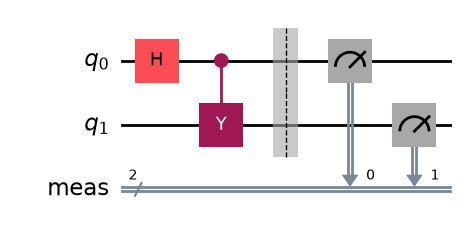

In [ ]:
"""Build the bell circuit (phi-plus state): it means hat both qubit are in the same state, either 00 or 11 as (qubit1 qubit0). 
The bell circuit is a simple example of entanglement, which is a key feature of quantum computing. 
In this circuit, we will create a bell state by applying a Hadamard gate to the first qubit 
and then applying a controlled-NOT (CNOT) gate to the second qubit. 
Finally, we will measure both qubits to observe their states."""
# we create a circuit of 2 qubits
bell_circuit = QuantumCircuit(2)
# add the hadamard gate to the first qubit
bell_circuit.h(0)
# Add the Controlled- Not gate to the  second qubit to create the entanglement with qubit 0
bell_circuit.cx(0, 1)
# add slot to measure the qubits value into classical bits
bell_circuit.measure_all()
# draw the circuit
bell_circuit.draw("mpl")


In [20]:
"""We will define a function to run the circuit on a simulator or real machine and retrieve the results."""

def run_circuit_and_get_counts(circuit:QuantumCircuit, backend:Backend, shots:int=1024)->dict:
    """Run the circuit on a simulator or real machine and retrieve the results.
    
    :param circuit: The quantum circuit to run.
    :param backend: the backend to run the circuit on (Qiskit backend of real device or simulator).
    :param shots: The number of shots to run the circuit for.
    :return: A dictionary counts of the measurement results.
    """
    # get the backend from the name
    preset_pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
    circuit_running = preset_pass_manager.run(circuit)
    # creation of the Sampler
    sampler = Sampler(mode=backend)
    # run the circuit on the backend as many times as specified by the shots parameter
    job = sampler.run([circuit_running], shots=shots)
    results = job.result()
    return results[0].data.meas.get_counts()
    

In [17]:
# retrieve the API key from the keyring
service_name = "https://quantum.cloud.ibm.com/"
username = "JulesVerneKey"
backend_name = "ibm_fez"  # all ibm backends start by ibm_ and follow by a city name, for example ibm_lagos, ibm_perth, ibm_cairo, ibm_mumbai, etc.
api_key = None
# retrieving the API KEY
api_key = keyring.get_password(service_name, username)
if api_key is None:
    print("failed to retrive the API Key")
else:
    print("API Key retrieved successfully")

API Key retrieved successfully


In [14]:
# run the circuit on a real quantum computer and retrieve the results

# part 1

# there are many way to save the account, either by directly instantiate the QiskitRuntimeService with the API key
# but that would mean it is provisory and would need to be done every time the notebook is run, or by using the static
# method save_account, the account data will be definitely saved in JSON file, and get be retreive anytime without giving
# again information, and a account can be set as default. This option give us more flexibility and is more secure, 
# as the API key is not stored in the notebook, but in a JSON file that can be encrypted.
QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token=api_key, overwrite=True, set_as_default=True)


In [24]:
# part 2
service = QiskitRuntimeService(channel="ibm_quantum_platform") # QiskitRuntimeService()
# print all existing backends
print(f"Available backends: {service.backends()}")
# select the least busy backend
backend = service.least_busy(operational=True, simulator=False, min_num_qubits=127)
if not backend.status().operational:
    # we take the first operational backend available from the list of available backends
    backend = [b for b in service.backends() if b.status().operational and not b.configuration().simulator and b.name != backend.name][0]
# or specify the backend by name directly
#backend = service.backend(backend_name)
print(f"selecting backend name: {backend.name} with {backend.num_qubits} qubits")

qiskit_runtime_service.__init__:WARNING:2026-08-06 16:23:28,224: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: JulesVerneInstance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-08-06 16:23:28,227: Loading instance: JulesVerneInstance, plan: open


Available backends: [<IBMBackend('ibm_fez')>, <IBMBackend('ibm_marrakesh')>, <IBMBackend('ibm_kingston')>]


qiskit_runtime_service.backends:WARNING:2026-08-06 16:23:29,919: Loading instance: JulesVerneInstance, plan: open
qiskit_runtime_service.backends:WARNING:2026-08-06 16:23:31,638: Using instance: JulesVerneInstance, plan: open


selecting backend name: ibm_marrakesh with 156 qubits


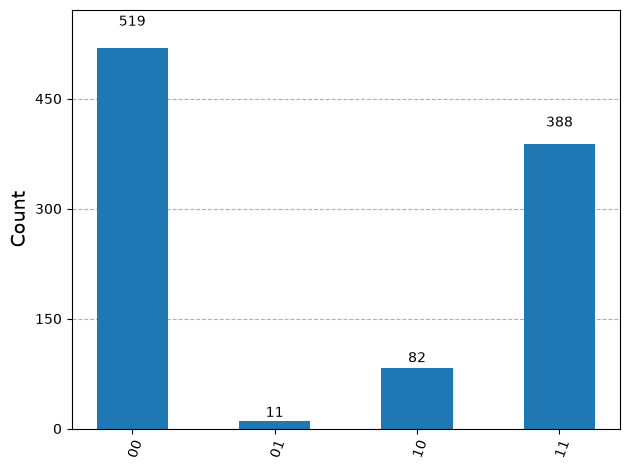

In [ ]:
counts = run_circuit_and_get_counts(bell_circuit, backend=backend, shots=1000)
plot_histogram(counts) # outcome in job d9q9hrfv9q4s73bi02pg

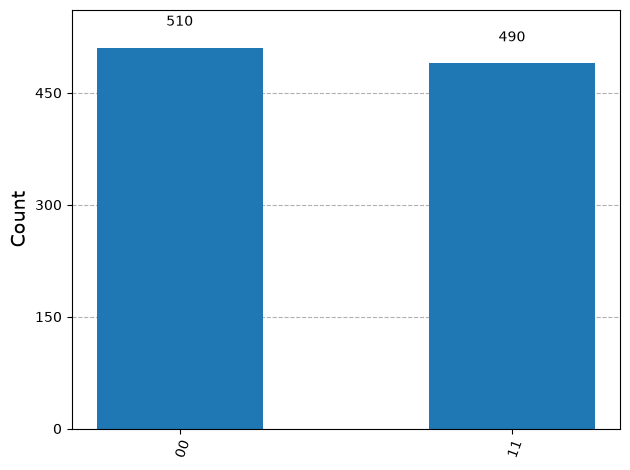

In [28]:
# case in simulator
backend = AerSimulator()
counts = run_circuit_and_get_counts(bell_circuit, backend=backend, shots=1000)
plot_histogram(counts)